# Carga y construcción del dataset

**Proyecto:** Predicción de la asistencia actual al nivel superior en jóvenes de 18 a 24 años con secundario completo (EPH – INDEC)

**Autora:** Liliana Elizabeth Iñigo

**Materia:** Aprendizaje Automático

**Docente:** Nicolás Caballero

Esta notebook carga las bases originales de la EPH y arma el dataset del proyecto:

1. Origen de los datos y archivos utilizados
2. Carga de las bases de personas y de hogares
3. Vinculación de cada joven con su hogar y con el jefe o jefa de hogar
4. Delimitación de la población de estudio
5. Variable objetivo y exclusión de respuestas desconocidas
6. Datos del hogar y del jefe/a
7. Ingreso del resto del hogar: situaciones y medida comparable entre trimestres
8. Variables excluidas por fuga de información
9. Panel: una fila por persona
10. Partición temporal y viviendas compartidas
11. Dataset final: instancias, columnas y tipos de datos

Es la primera de tres notebooks:

| Notebook | Contenido |
|---|---|
| **`1.0-lei-carga-y-construccion-dataset`** | Carga de las bases y construcción del dataset (esta notebook) |
| `2.0-lei-analisis-exploratorio` | Análisis exploratorio de datos (EDA), solo con el conjunto de entrenamiento |
| `3.0-lei-preprocesamiento` | Limpieza, transformaciones, codificación y escalado |

El mismo procesamiento de esta notebook está en el script `asistencia_superior/dataset.py`, que genera los archivos de `data/interim` y `data/processed`. La documentación del dataset (origen, variables y diccionario) está en `docs/informe_dataset.md`.

> **Criterio general:** las decisiones de esta notebook se basan en **reglas sobre el significado de los códigos** (definidas en el diseño de registro del INDEC) o en la **estructura de la encuesta**. No se toman decisiones a partir de frecuencias o relaciones observadas en los datos de prueba.

## Planteo de la predicción

- **Variable objetivo:** `asiste_superior` (1 = asiste actualmente a un estudio superior · 0 = no asiste actualmente).
- **Cada fila** es un joven de 18 a 24 años con secundario completo y sin estudio superior terminado, con su situación y la de su hogar en el trimestre en que fue encuestado (una sola fila por persona).
- **Momento de la predicción:** el de la encuesta. Solo se usan datos que pueden conocerse sin saber si el joven asiste: características personales, del hogar, del jefe/a y ubicación. Se excluye todo lo que contiene la respuesta o es consecuencia de estudiar (ver sección 8).
- **Dos tiempos:**
  1. **Uso:** estimar la asistencia de un joven a partir de sus datos y los de su hogar.
  2. **Evaluación con la realidad y corrección:** cada trimestre el INDEC publica una nueva EPH con la respuesta real; con ella se puede comparar lo estimado con lo observado y corregir.

## 1. Origen de los datos

- **Fuente:** Encuesta Permanente de Hogares (EPH), modalidad continua, Instituto Nacional de Estadística y Censos (INDEC).
- **Sitio de descarga:** https://www.indec.gob.ar/indec/web/Institucional-Indec-BasesDeDatos
- **Documentación de los códigos:** diseño de registro de las bases de usuarios de la EPH (INDEC, 1.er trimestre de 2025): https://www.indec.gob.ar/ftp/cuadros/menusuperior/eph/EPH_registro_1T2025.pdf
- **Trimestres:** 2.º, 3.º y 4.º trimestre de 2025 y 1.er trimestre de 2026 (los cuatro más recientes publicados al momento de la descarga).
- **Fecha de descarga:** 22 de octubre de 2026.
- **Formato:** archivos de texto separados por punto y coma (`;`). Por cada trimestre hay una base de **personas** (`usu_individual_*`) y una de **hogares** (`usu_hogar_*`).
- **Cobertura geográfica:** 31 aglomerados urbanos (32 códigos de `AGLOMERADO`, porque el Gran Buenos Aires se divide en Ciudad de Buenos Aires y partidos del conurbano). La EPH no cubre la población rural, por eso el estudio habla de jóvenes de los aglomerados urbanos relevados y no de todos los jóvenes del país.
- **Licencia de uso:** datos públicos del INDEC; se cita la fuente.

In [1]:
# Librerías y constantes: carpeta de datos originales, trimestres y claves de vinculación
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 40)
# Rutas relativas a la carpeta notebooks/ del repositorio. Si se ejecuta desde otra ubicación,
# reemplazar por la ruta local donde se encuentran los archivos originales de la EPH
RAW = Path("../data/raw")
TRIMESTRES = ["T225", "T325", "T425", "T126"]
CLAVE_HOGAR = ["CODUSU", "NRO_HOGAR", "ANO4", "TRIMESTRE"]
CLAVE_PERSONA = ["CODUSU", "NRO_HOGAR", "COMPONENTE"]

## 2. Carga de las bases

Cada archivo se lee con separador `;`. Algunos trimestres traen los encabezados entre comillas y otros no; `pandas` los lee igual. Los montos con decimales (por ejemplo, el ingreso per cápita familiar `IPCF`) están escritos con **coma decimal** (`466666,67`), por eso se indica `decimal=","`; sin esa opción esas columnas se leerían como texto.

In [2]:
# Lectura de las 8 bases (separador ';', coma decimal) y resumen de filas y columnas por archivo
personas_t = {t: pd.read_csv(RAW / f"usu_individual_{t}.txt", sep=";", decimal=",", low_memory=False) for t in TRIMESTRES}
hogares_t = {t: pd.read_csv(RAW / f"usu_hogar_{t}.txt", sep=";", decimal=",", low_memory=False) for t in TRIMESTRES}

resumen = pd.DataFrame({
    "trimestre": TRIMESTRES,
    "personas (filas)": [len(personas_t[t]) for t in TRIMESTRES],
    "columnas base personas": [personas_t[t].shape[1] for t in TRIMESTRES],
    "hogares (filas)": [len(hogares_t[t]) for t in TRIMESTRES],
    "columnas base hogares": [hogares_t[t].shape[1] for t in TRIMESTRES],
})
resumen.loc["Total"] = ["", resumen["personas (filas)"].sum(), "", resumen["hogares (filas)"].sum(), ""]
resumen

,trimestre,personas (filas),columnas base personas,hogares (filas),columnas base hogares
0,T225,46086,235,16169,98
1,T325,44946,235,15860,98
2,T425,43703,235,15534,98
3,T126,43739,234,15447,98
Total,,178474,,63010,


**Diferencia de diseño entre trimestres:** la base de personas del 1.er trimestre de 2026 tiene una columna menos. Se verifica cuál es:

In [3]:
# Comparación de columnas entre un trimestre de 2025 y el de 2026 (cambio de diseño de registro)
cols_2025 = set(personas_t["T425"].columns)
cols_2026 = set(personas_t["T126"].columns)
print("Columnas que están en 2025 y no en 1T 2026:", sorted(cols_2025 - cols_2026))
print("Columnas que están en 1T 2026 y no en 2025:", sorted(cols_2026 - cols_2025))

Columnas que están en 2025 y no en 1T 2026: ['CAT_INAC']
Columnas que están en 1T 2026 y no en 2025: []


La columna que falta es `CAT_INAC` (categoría de inactividad). No afecta al proyecto porque se excluye de todas formas: una de sus categorías es "estudiante" (ver sección 8).

In [4]:
# Unión de los cuatro trimestres en una base de personas y una de hogares
personas = pd.concat(personas_t.values(), ignore_index=True)
hogares = pd.concat(hogares_t.values(), ignore_index=True)
print("Personas (4 trimestres):", f"{len(personas):,}")
print("Hogares  (4 trimestres):", f"{len(hogares):,}")

Personas (4 trimestres): 178,474
Hogares  (4 trimestres): 63,010


## 3. Vinculación persona – hogar – jefe o jefa de hogar

- **Persona con su hogar:** las dos bases comparten `CODUSU` (vivienda) y `NRO_HOGAR` (hogar dentro de la vivienda). Como hay cuatro trimestres, se agregan `ANO4` y `TRIMESTRE` a la clave.
- **Persona con el jefe o jefa de hogar:** dentro del mismo hogar, el jefe o jefa es quien tiene `CH03 = 1` (relación de parentesco). De esa fila se toman su nivel educativo (`NIVEL_ED`), su sexo (`CH04`) y su condición de actividad (`ESTADO`).

In [5]:
# Controles de las claves: cada hogar debe aparecer una vez y tener un solo jefe/a (CH03 = 1)
hogares_por_clave = hogares.duplicated(CLAVE_HOGAR).sum()
jefes = personas.loc[personas["CH03"] == 1, CLAVE_HOGAR + ["NIVEL_ED", "CH04", "ESTADO"]]
print("Claves de hogar repetidas en la base de hogares:", hogares_por_clave)
print("Hogares con más de un jefe/a:", jefes.duplicated(CLAVE_HOGAR).sum())

claves_personas = personas[CLAVE_HOGAR].drop_duplicates()
con_hogar = claves_personas.merge(hogares[CLAVE_HOGAR], how="inner").shape[0]
con_jefe = claves_personas.merge(jefes[CLAVE_HOGAR], how="inner").shape[0]
print(f"Hogares de la base de personas que encuentran su fila en la base de hogares: {con_hogar / len(claves_personas):.1%}")
print(f"Hogares de la base de personas que tienen un jefe/a identificado: {con_jefe / len(claves_personas):.1%}")

Claves de hogar repetidas en la base de hogares: 0
Hogares con más de un jefe/a: 0
Hogares de la base de personas que encuentran su fila en la base de hogares: 100.0%
Hogares de la base de personas que tienen un jefe/a identificado: 100.0%


## 4. Población de estudio

Se trabaja con jóvenes de **18 a 24 años** (`CH06`) que **terminaron el secundario y no completaron un estudio superior**.

Para el filtro se usa `NIVEL_ED` (nivel educativo alcanzado), según el diseño de registro de la EPH:

| NIVEL_ED | Significado | ¿Se incluye? |
|---|---|---|
| 1, 2, 3, 7 | Primaria incompleta/completa, secundaria incompleta, sin instrucción | No (no terminaron el secundario) |
| **4** | Secundario completo | **Sí** |
| **5** | Superior universitario incompleto | **Sí** |
| 6 | Superior universitario completo | No (ya terminaron un estudio superior) |

Se incluye el código 5 porque quien terminó el secundario y **está cursando** el nivel superior figura con `NIVEL_ED = 5`, no con 4. Si se filtrara solo por 4, quedarían afuera justamente los jóvenes que asisten.

Se excluye el código 6 porque no asistir actualmente no significa que no hayan accedido: ya terminaron una carrera.

In [6]:
# Nivel educativo alcanzado (NIVEL_ED) de los jóvenes de 18 a 24 años, para documentar el filtro
edad_ok = personas["CH06"].between(18, 24)
conteo_nivel = personas.loc[edad_ok, "NIVEL_ED"].value_counts().sort_index()
conteo_nivel.index = conteo_nivel.index.map({1: "1 Primaria incompleta", 2: "2 Primaria completa",
    3: "3 Secundaria incompleta", 4: "4 Secundaria completa", 5: "5 Superior incompleto",
    6: "6 Superior completo", 7: "7 Sin instrucción"})
conteo_nivel.rename("jóvenes de 18 a 24 años").to_frame()

,jóvenes de 18 a 24 años
NIVEL_ED,
1 Primaria incompleta,353
2 Primaria completa,430
3 Secundaria incompleta,4638
4 Secundaria completa,5609
5 Superior incompleto,8274
6 Superior completo,502
7 Sin instrucción,25


In [7]:
# Filtro de la población: 18 a 24 años y NIVEL_ED 4 o 5; se cuentan los excluidos por superior completo
poblacion = personas[edad_ok & personas["NIVEL_ED"].isin([4, 5])].copy()
excluidos_superior_completo = (edad_ok & (personas["NIVEL_ED"] == 6)).sum()
print(f"Observaciones en la población de estudio: {len(poblacion):,}")
print(f"Excluidos por tener un estudio superior completo (NIVEL_ED = 6): {excluidos_superior_completo:,}")
poblacion.groupby(["ANO4", "TRIMESTRE"]).size().rename("observaciones").to_frame()

Observaciones en la población de estudio: 13,883
Excluidos por tener un estudio superior completo (NIVEL_ED = 6): 502


observaciones
ANO4 TRIMESTRE               
2025 2                   3726
     3                   3437
     4                   3223
2026 1                   3497

## 5. Variable objetivo: `asiste_superior`

La respuesta surge directamente de dos preguntas de la encuesta:

- `CH10`: ¿asiste o asistió a algún establecimiento educativo? (1 = sí, asiste · 2 = no asiste, pero asistió · 3 = nunca asistió)
- `CH12`: ¿cuál es el nivel más alto que cursa o cursó? (6 = terciario · 7 = universitario · 8 = posgrado universitario, entre otros)

`CH12` también registra niveles cursados **en el pasado**, por eso se interpreta siempre junto con `CH10`:

- **`asiste_superior = 1`**: asiste actualmente (`CH10 = 1`) y el nivel que cursa es terciario, universitario o posgrado (`CH12` = 6, 7 u 8).
- **`asiste_superior = 0`**: no asiste actualmente al nivel superior (`CH10` = 2 o 3, o asiste a otro nivel).

La variable describe la situación **en el momento de la encuesta**: no permite afirmar qué hará el joven en el futuro.

In [8]:
# Variable objetivo: asiste (CH10 = 1) a terciario, universitario o posgrado (CH12 = 6, 7, 8)
poblacion["asiste_superior"] = ((poblacion["CH10"] == 1) & poblacion["CH12"].isin([6, 7, 8])).astype(int)

# Respuesta conocida: CH10 con un código válido (1, 2 o 3) y, si asiste, un nivel válido en CH12 (1 a 9)
poblacion["respuesta_conocida"] = (
    poblacion["CH10"].isin([1, 2, 3]) & ~((poblacion["CH10"] == 1) & ~poblacion["CH12"].between(1, 9))
).astype(int)

# La tabla cruzada muestra cómo queda clasificada cada combinación de CH10 y CH12
pd.crosstab([poblacion["CH10"], poblacion["CH12"]],
            poblacion["asiste_superior"].where(poblacion["respuesta_conocida"] == 1).map({0: "0", 1: "1"})
            .fillna("desconocida"), margins=True, margins_name="Total")

asiste_superior     0     1  desconocida  Total
CH10  CH12                                     
0     0             0     0            1      1
1     6             0  1722            0   1722
      7             0  6063            0   6063
      99            0     0            1      1
2     2             1     0            0      1
      3             2     0            0      2
      4          5268     0            0   5268
      5           335     0            0    335
      6           149     0            0    149
      7           339     0            0    339
      99            1     0            0      1
9     99            0     0            1      1
Total            6095  7785            3  13883

**Respuestas desconocidas.** Hay 3 observaciones cuya asistencia al nivel superior **no puede determinarse**: una declara asistir (`CH10 = 1`) pero no tiene dato de nivel (`CH12 = 99`), y dos no tienen dato válido en `CH10` (códigos 0 y 9). Desconocer la respuesta no equivale a una respuesta negativa, por eso **no se les asigna la clase 0: se excluyen del conjunto supervisado**. No se las imputa porque la encuesta no ofrece otra información válida que permita saber si asisten. En la sección 9 se verifica cuántas personas se pierden después de conservar una observación por persona.

También se ve que 149 jóvenes cursaron un terciario y 339 una carrera universitaria pero **ya no asisten** (`CH10 = 2`): quedan en la clase 0 porque la variable mide la asistencia actual y en ellos la respuesta sí es conocida.

`CH10`, `CH12` y `NIVEL_ED` se usan **solo** para definir la población y la respuesta: no se guardan como predictoras en el dataset final.

## 6. Datos del hogar y del jefe o jefa

Se agregan a cada joven:

- de la **base de hogares**: tipo de vivienda (`IV1`), cantidad de ambientes (`II1`), régimen de tenencia (`II7`), cantidad de personas (`IX_TOT`) y de menores de 10 años (`IX_MEN10`);
- del **jefe o jefa de hogar**: nivel educativo, sexo y condición de actividad.

**Jóvenes que son ellos mismos jefe/a de hogar** (`CH03 = 1`): para ellos, "educación del jefe/a" sería su propio nivel educativo, que contiene la respuesta. En esos casos los datos del jefe/a quedan vacíos ("no aplica") y se marca `es_jefe_hogar = 1`.

**Jóvenes que son cónyuges del jefe/a** (`CH03 = 2`): los datos del jefe/a corresponden a **otra persona** (su pareja), así que se conservan como para cualquier otro integrante del hogar.

In [9]:
# Se agregan los datos del hogar (base de hogares) y del jefe/a (persona con CH03 = 1 del mismo hogar)
datos_jefe = jefes.rename(columns={"NIVEL_ED": "jefe_nivel_ed", "CH04": "jefe_sexo", "ESTADO": "jefe_estado"})
poblacion = poblacion.merge(hogares[CLAVE_HOGAR + ["IV1", "II1", "II7", "IX_TOT", "IX_MEN10"]],
                            on=CLAVE_HOGAR, how="left", validate="m:1")
poblacion = poblacion.merge(datos_jefe, on=CLAVE_HOGAR, how="left", validate="m:1")

# Solo si el joven es el propio jefe/a, sus datos de "jefe" no aplican (serían su propia información)
poblacion["es_jefe_hogar"] = (poblacion["CH03"] == 1).astype(int)
for col in ["jefe_nivel_ed", "jefe_sexo", "jefe_estado"]:
    poblacion.loc[poblacion["es_jefe_hogar"] == 1, col] = np.nan

# Hacinamiento: personas por ambiente de uso exclusivo del hogar
poblacion["personas_por_ambiente"] = poblacion["IX_TOT"] / poblacion["II1"].where(poblacion["II1"] > 0)
poblacion["trimestre_id"] = poblacion["ANO4"].astype(str) + "T" + poblacion["TRIMESTRE"].astype(str)

print("Observaciones de jóvenes que son jefe/a de hogar:", poblacion["es_jefe_hogar"].sum())
print("Observaciones de jóvenes cónyuges (conservan los datos del jefe/a):", (poblacion["CH03"] == 2).sum())
print("Jóvenes sin datos de hogar:", poblacion["IX_TOT"].isna().sum())

Observaciones de jóvenes que son jefe/a de hogar: 1346
Observaciones de jóvenes cónyuges (conservan los datos del jefe/a): 444
Jóvenes sin datos de hogar: 0


## 7. Ingreso del resto del hogar

El ingreso propio del joven (`P47T`) incluye becas de estudio y cuotas de alimentos, que pueden depender de que estudie (sección 8). Por eso se usa el **ingreso per cápita del resto del hogar**: (ingreso total familiar `ITF` − ingreso del joven `P47T`) / (integrantes − 1).

### 7.1 Cuatro situaciones distintas

Un valor faltante o igual a 0 puede significar cosas muy distintas, así que se separan las situaciones con la variable `situacion_ingreso_resto`:

| Situación | Regla | Monto |
|---|---|---|
| `no_aplica_vive_solo` | El hogar tiene 1 integrante (`IX_TOT = 1`): no hay "resto del hogar" | Vacío (no aplica) |
| `sin_respuesta` | El hogar no respondió ingresos (`DECCFR = 12`, "no respuesta de ingresos" en el diseño de registro) | Vacío (desconocido) |
| `cero_observado` | El hogar respondió y el resto de los integrantes no tiene ingresos | 0 (dato válido) |
| `positivo` | El hogar respondió y el resto tiene ingresos | El monto calculado |

In [10]:
# Situaciones del ingreso del resto del hogar
vive_solo = poblacion["IX_TOT"] == 1
sin_respuesta = poblacion["DECCFR"] == 12
ingreso_propio = poblacion["P47T"].where(poblacion["P47T"] >= 0)        # -9 = sin dato
resto = poblacion["ITF"] - ingreso_propio

# Control: antes de calcular, se verifica que la resta nunca sea negativa (si lo fuera, habría una inconsistencia)
negativos = (resto[~sin_respuesta & ~vive_solo] < 0).sum()
print("Observaciones con ITF menor que el ingreso del joven (resta negativa):", negativos)

poblacion["ingreso_resto_hogar_pc"] = (resto / (poblacion["IX_TOT"] - 1)).where(~sin_respuesta & ~vive_solo)
poblacion["situacion_ingreso_resto"] = np.select(
    [vive_solo, sin_respuesta, poblacion["ingreso_resto_hogar_pc"] == 0],
    ["no_aplica_vive_solo", "sin_respuesta", "cero_observado"], default="positivo")
poblacion["situacion_ingreso_resto"].value_counts().rename("observaciones").to_frame()

Observaciones con ITF menor que el ingreso del joven (resta negativa): 0


,observaciones
situacion_ingreso_resto,
positivo,8927
sin_respuesta,4024
no_aplica_vive_solo,742
cero_observado,190


In [11]:
# ¿Por qué hay ceros observados? Se verifica si son ingresos nulos reales o inconsistencias
ceros = poblacion[poblacion["situacion_ingreso_resto"] == "cero_observado"]
motivo = np.where(ceros["ITF"] == 0, "El hogar declaró ingreso total 0",
                  np.where(ceros["ITF"] == ceros["P47T"], "Todo el ingreso del hogar es del joven", "Otro"))
pd.Series(motivo).value_counts().rename("observaciones").to_frame()

,observaciones
Todo el ingreso del hogar es del joven,151
El hogar declaró ingreso total 0,39


**Lectura:** no hay restas negativas, así que no hace falta recortar valores. Los ceros observados son **ingresos nulos reales**: o bien el hogar declaró un ingreso total de 0, o bien todo el ingreso del hogar es del propio joven (los demás integrantes no tienen ingresos). No se detectaron inconsistencias. El 0 se conserva como **dato válido**, distinto de "vive solo" y de "sin respuesta".

### 7.2 Comparabilidad entre trimestres

Los montos están en **pesos corrientes** de cada trimestre. Con inflación, el mismo monto no representa lo mismo en 2025 que en 2026, y eso importa porque el entrenamiento usa 2025 y la prueba usa 2026. El logaritmo o la estandarización no resuelven esto: no llevan los montos a una misma base de precios.

**Medida comparable elegida: el percentil del ingreso dentro de su propio trimestre.** Para cada trimestre se toma la distribución del ingreso per cápita familiar (`IPCF`) de **todas las personas de la EPH** de ese trimestre cuyo hogar respondió ingresos, ponderada con `PONDIH` (el ponderador de ingresos del INDEC). El percentil de un joven indica qué porcentaje de esa población tiene un ingreso per cápita menor o igual al de su hogar. Es la misma lógica de los deciles que publica el INDEC (`DECCFR`), que también se calculan dentro de cada trimestre.

Ventajas: no depende de un índice de precios externo y expresa la posición relativa del hogar, que es comparable entre trimestres. La distribución de referencia es la de toda la encuesta del trimestre y no usa la variable objetivo. Limitación: se pierde el nivel absoluto del ingreso (dos hogares en el mismo percentil de trimestres distintos pueden tener poder de compra algo diferente).

In [12]:
# Percentil del ingreso del resto del hogar dentro de la distribución ponderada del IPCF de su trimestre
def percentil_en_trimestre(valores, trimestre, personas):
    resultado = pd.Series(np.nan, index=valores.index)
    respondieron = personas[personas["DECCFR"].between(0, 10)]          # hogares con respuesta de ingresos
    for (anio, trim), grupo in respondieron.groupby(["ANO4", "TRIMESTRE"]):
        orden = grupo.sort_values("IPCF")
        acumulado = orden["PONDIH"].cumsum().to_numpy() / orden["PONDIH"].sum()
        filas = (trimestre == f"{anio}T{trim}") & valores.notna()
        posicion = np.searchsorted(orden["IPCF"].to_numpy(), valores[filas].to_numpy(), side="right")
        resultado[filas] = np.where(posicion > 0, acumulado[np.maximum(posicion - 1, 0)], 0.0) * 100
    return resultado

poblacion["percentil_ingreso_resto"] = percentil_en_trimestre(
    poblacion["ingreso_resto_hogar_pc"], poblacion["trimestre_id"], personas)

# Comparación por trimestre: el monto en pesos sube por la inflación; el percentil se mantiene estable
positivos = poblacion[poblacion["situacion_ingreso_resto"] == "positivo"]
positivos.groupby("trimestre_id").agg(
    mediana_en_pesos=("ingreso_resto_hogar_pc", "median"),
    mediana_del_percentil=("percentil_ingreso_resto", "median")).round(0)

,mediana_en_pesos,mediana_del_percentil
trimestre_id,,
2025T2,410000.0,53.0
2025T3,493333.0,53.0
2025T4,500000.0,56.0
2026T1,526519.0,52.0


**Lectura:** la mediana en pesos del ingreso del resto del hogar crece trimestre a trimestre, mientras que la mediana del percentil se mantiene en un rango parecido. Esto muestra que los pesos corrientes no son comparables entre períodos y que el percentil sí ofrece una referencia común. En la preparación (notebook 3.0) se usa el **percentil** como variable de ingreso; el monto en pesos se conserva en el dataset solo como referencia.

## 8. Variables excluidas por fuga de información

Una variable "filtra" la respuesta cuando contiene la información que se quiere predecir o es **consecuencia** de ella, de modo que **no estaría disponible, o no tendría sentido usarla, en el escenario de uso**: estimar si un joven asiste a partir de sus características y las de su hogar, por ejemplo para orientar becas o acompañamientos.

Que una variable esté muy asociada con la asistencia **no demuestra por sí solo** que haya fuga. Por eso cada exclusión se justifica por la **definición de la variable** en el diseño de registro del INDEC (1T 2025):

| Variable | Definición (diseño de registro) | Por qué se excluye |
|---|---|---|
| `CH10`, `CH12` | Asistencia a un establecimiento y nivel que cursa | Construyen la respuesta |
| `NIVEL_ED` | Nivel educativo alcanzado | Se usa para delimitar la población; quien cursa el superior figura con 5: contiene la respuesta |
| `CH11`, `CH13`, `CH14` | Tipo de establecimiento al que asiste, si finalizó el nivel, último año aprobado | Preguntas sobre la propia trayectoria educativa, que se responden según la asistencia |
| `CAT_INAC` | Categoría de inactividad: 1 Jubilado/pensionado · 2 Rentista · **3 Estudiante** · 4 Ama de casa · … | La categoría "Estudiante" es la respuesta misma. Además no existe en 1T 2026 |
| `V11_01_M` | "Monto del ingreso por una beca de estudio (en dinero) del gobierno para continuar estudios o finalizarlos" (por ejemplo, Progresar) | Una beca para continuar estudios supone estar estudiando: es consecuencia de la asistencia. En el escenario de uso (orientar becas) además sería circular |
| `V11_02_M` | "Monto del ingreso por otra beca de estudio (en dinero) de instituciones no gubernamentales" | Ídem: requiere estar estudiando |
| `V12_M` | "Monto del ingreso por cuotas de alimentos o ayuda en dinero de personas que no viven en el hogar" | Puede depender de que el joven estudie: la cuota alimentaria puede extenderse hasta los 25 años si el hijo estudia (art. 663 del Código Civil y Comercial) y la ayuda en dinero de personas de afuera del hogar incluye la que reciben jóvenes que se mudaron para estudiar |
| `P47T`, `ITF`, `IPCF` y deciles del joven | Ingresos que incluyen los montos anteriores | Se reemplazan por el ingreso del resto del hogar (sección 7) |

Como **comprobación complementaria** (no como fundamento de la decisión), se muestra la relación de estas variables con la asistencia usando **solo las observaciones de 2025**, que corresponden al período de entrenamiento, para no usar datos de prueba:

In [13]:
# Comprobación complementaria, solo con observaciones de 2025 (período de entrenamiento)
obs_2025 = poblacion[(poblacion["ANO4"] == 2025) & (poblacion["respuesta_conocida"] == 1)]

print("NIVEL_ED del joven vs. asiste_superior (proporción por fila):")
print(pd.crosstab(obs_2025["NIVEL_ED"], obs_2025["asiste_superior"], normalize="index").round(3))

tiene_beca = (obs_2025["V11_01_M"] > 0) | (obs_2025["V11_02_M"] > 0)
print("\nRecibe beca de estudio (V11_01_M o V11_02_M):")
print(pd.crosstab(tiene_beca, obs_2025["asiste_superior"], margins=True))
print("\nRecibe cuota de alimentos o ayuda de personas fuera del hogar (V12_M):")
print(pd.crosstab(obs_2025["V12_M"] > 0, obs_2025["asiste_superior"], margins=True))
print("\nCategoría de inactividad 3 'Estudiante' (CAT_INAC):")
print(pd.crosstab(obs_2025["CAT_INAC"] == 3, obs_2025["asiste_superior"], margins=True))

NIVEL_ED del joven vs. asiste_superior (proporción por fila):
asiste_superior      0      1
NIVEL_ED                     
4                1.000  0.000
5                0.056  0.944

Recibe beca de estudio (V11_01_M o V11_02_M):
asiste_superior     0     1    All
row_0                             
False            4452  5434   9886
True               18   479    497
All              4470  5913  10383

Recibe cuota de alimentos o ayuda de personas fuera del hogar (V12_M):
asiste_superior     0     1    All
V12_M                             
False            4397  5144   9541
True               73   769    842
All              4470  5913  10383

Categoría de inactividad 3 'Estudiante' (CAT_INAC):
asiste_superior     0     1    All
CAT_INAC                          
False            4470  1571   6041
True                0  4342   4342
All              4470  5913  10383


**Lectura:** las tablas son coherentes con las definiciones (por ejemplo, casi todos los que cobran una beca de estudio asisten y la categoría "Estudiante" coincide con la respuesta), pero la decisión se apoya en la definición de cada variable y en el escenario de uso, no en estas proporciones.

**Variable a vigilar ("zona gris"):** `condicion_actividad` (`ESTADO`: ocupado, desocupado, inactivo). No es un indicador educativo y está disponible en el escenario de uso, pero se mide al mismo tiempo que la asistencia y en parte puede ser consecuencia de estudiar. Se conserva y queda señalada.

## 9. Panel: una fila por persona

La EPH vuelve a encuestar a los mismos hogares en trimestres sucesivos. Una persona se identifica con `CODUSU` + `NRO_HOGAR` + `COMPONENTE`. Se conserva **una sola observación por persona: la más reciente entre las que tienen respuesta conocida**. Así, si una persona tiene una observación con respuesta desconocida y otra válida, se usa la válida.

In [14]:
# Panel: cuántas veces aparece cada persona y cuántas personas se pierden por respuestas desconocidas
apariciones = poblacion.groupby(CLAVE_PERSONA).size()
validas = poblacion[poblacion["respuesta_conocida"] == 1]
personas_validas = validas[CLAVE_PERSONA].drop_duplicates()
print(f"Observaciones de la población: {len(poblacion):,}")
print(f"Personas distintas: {apariciones.size:,}")
print(f"Observaciones con respuesta desconocida excluidas: {(poblacion['respuesta_conocida'] == 0).sum()}")
print(f"Personas que quedan con al menos una observación válida: {len(personas_validas):,} "
      f"(se pierden {apariciones.size - len(personas_validas)})")
apariciones.value_counts().sort_index().rename_axis("veces que aparece").rename("personas").to_frame()

Observaciones de la población: 13,883
Personas distintas: 9,665
Observaciones con respuesta desconocida excluidas: 3
Personas que quedan con al menos una observación válida: 9,663 (se pierden 2)


,personas
veces que aparece,
1,5447
2,4218


In [15]:
# Se conserva la observación más reciente con respuesta conocida de cada persona
una_por_persona = validas.sort_values(["ANO4", "TRIMESTRE"]).drop_duplicates(CLAVE_PERSONA, keep="last").copy()
una_por_persona["trimestre_id"].value_counts().sort_index().rename("personas (observación conservada)").to_frame()

,personas (observación conservada)
trimestre_id,
2025T2,1894
2025T3,2151
2025T4,2121
2026T1,3497


**Lectura:** de las 3 observaciones con respuesta desconocida, una pertenece a una persona que tiene otra observación válida en otro trimestre (se usa esa), y las otras dos corresponden a personas sin ninguna observación válida: **se pierden 2 personas** y el dataset queda con **9.663 jóvenes**.

## 10. Partición temporal y viviendas compartidas

La partición en entrenamiento y prueba se define por una **regla temporal**, antes de cualquier análisis exploratorio:

- **Entrenamiento:** observaciones de 2025 (2.º, 3.º y 4.º trimestre).
- **Prueba:** observaciones del 1.er trimestre de 2026.

Así se simula el uso previsto: aprender con datos pasados y comprobar con una EPH más nueva. Como hay una sola fila por persona, ninguna persona queda en los dos conjuntos.

**Viviendas compartidas.** Además de personas, conviene revisar las **viviendas**: la EPH vuelve a visitar las mismas viviendas, y un hermano o conviviente puede quedar en entrenamiento (2025) mientras otro joven de la misma vivienda queda en prueba (2026). Comparten las características del hogar y suelen tener situaciones parecidas, así que el modelo podría "reconocer" el hogar y la prueba se vería mejor de lo que es.

En el uso real, el modelo se aplicaría a jóvenes de una EPH nueva; algunos podrían vivir en viviendas ya encuestadas, pero la evaluación más exigente (y la que no sobreestima el desempeño) es sobre viviendas **no vistas** en el entrenamiento. Por eso **se excluyen del entrenamiento** los jóvenes de 2025 que viven en una vivienda que también tiene jóvenes en la prueba. La prueba no se modifica.

In [16]:
# Partición temporal y control de viviendas (CODUSU) presentes en ambos conjuntos
es_prueba = una_por_persona["trimestre_id"] == "2026T1"
viviendas_prueba = set(una_por_persona.loc[es_prueba, "CODUSU"])
compartida = ~es_prueba & una_por_persona["CODUSU"].isin(viviendas_prueba)
una_por_persona["particion"] = np.select([es_prueba, compartida],
                                         ["prueba", "excluida_vivienda_en_prueba"], "entrenamiento")

hogares_entrenamiento = una_por_persona.loc[~es_prueba, ["CODUSU", "NRO_HOGAR"]].drop_duplicates()
hogares_prueba = una_por_persona.loc[es_prueba, ["CODUSU", "NRO_HOGAR"]].drop_duplicates()
print("Viviendas con jóvenes en 2025 y en 1T 2026:", len(set(una_por_persona.loc[~es_prueba, "CODUSU"]) & viviendas_prueba))
print("Hogares (vivienda + hogar) con jóvenes en 2025 y en 1T 2026:", len(hogares_entrenamiento.merge(hogares_prueba)))
print("Personas compartidas entre 2025 y 1T 2026:",
      len(una_por_persona.loc[~es_prueba, CLAVE_PERSONA].merge(una_por_persona.loc[es_prueba, CLAVE_PERSONA])))
una_por_persona["particion"].value_counts().rename("jóvenes").to_frame()

Viviendas con jóvenes en 2025 y en 1T 2026: 100
Hogares (vivienda + hogar) con jóvenes en 2025 y en 1T 2026: 92
Personas compartidas entre 2025 y 1T 2026: 0


,jóvenes
particion,
entrenamiento,6059
prueba,3497
excluida_vivienda_en_prueba,107


**Lectura:** 100 viviendas tienen jóvenes en los dos períodos (92 si se cuenta el hogar dentro de la vivienda; se usa la vivienda porque es el criterio más estricto). Sus 107 jóvenes de 2025 se marcan como `excluida_vivienda_en_prueba` y no se usan para entrenar. Quedan **6.059 jóvenes para entrenamiento** y **3.497 para prueba**, sin personas ni viviendas compartidas.

## 11. Dataset final

Se seleccionan las columnas del dataset procesado con nombres descriptivos. Los códigos de cada variable categórica están en el diccionario de `docs/informe_dataset.md`.

In [17]:
# Selección de columnas del dataset final con nombres descriptivos
columnas = {
    "CODUSU": "codusu", "NRO_HOGAR": "nro_hogar", "COMPONENTE": "componente",
    "trimestre_id": "trimestre", "particion": "particion", "PONDERA": "ponderador",
    "asiste_superior": "asiste_superior",
    "CH04": "sexo", "CH06": "edad", "CH03": "parentesco_jefe", "es_jefe_hogar": "es_jefe_hogar",
    "CH07": "estado_civil", "CH08": "cobertura_salud", "CH15": "lugar_nacimiento",
    "ESTADO": "condicion_actividad", "IX_TOT": "personas_hogar", "IX_MEN10": "menores_10_hogar",
    "personas_por_ambiente": "personas_por_ambiente", "IV1": "tipo_vivienda", "II7": "tenencia_vivienda",
    "situacion_ingreso_resto": "situacion_ingreso_resto", "ingreso_resto_hogar_pc": "ingreso_resto_hogar_pc",
    "percentil_ingreso_resto": "percentil_ingreso_resto",
    "jefe_nivel_ed": "jefe_nivel_educativo", "jefe_sexo": "jefe_sexo", "jefe_estado": "jefe_condicion_actividad",
    "REGION": "region", "AGLOMERADO": "aglomerado",
}
dataset = una_por_persona[list(columnas)].rename(columns=columnas).reset_index(drop=True)
print(f"Instancias: {dataset.shape[0]:,}  |  Columnas: {dataset.shape[1]}")
dataset.head()

Instancias: 9,663  |  Columnas: 28


,codusu,nro_hogar,componente,trimestre,particion,ponderador,asiste_superior,sexo,edad,parentesco_jefe,es_jefe_hogar,estado_civil,cobertura_salud,lugar_nacimiento,condicion_actividad,personas_hogar,menores_10_hogar,personas_por_ambiente,tipo_vivienda,tenencia_vivienda,situacion_ingreso_resto,ingreso_resto_hogar_pc,percentil_ingreso_resto,jefe_nivel_educativo,jefe_sexo,jefe_condicion_actividad,region,aglomerado
0,TQRMNOQWSHMKMPCDEIIAD00878792,1,3,2025T2,entrenamiento,843,0,2,22,3,0,5,4.0,1,1,3,0,0.750000,1,2,positivo,700000.000000,78.211536,4.0,1.0,1.0,1,32
1,TQRMNOPWXHJOLUCDEFKID00863481,1,2,2025T2,entrenamiento,1044,0,2,22,3,0,1,4.0,1,3,3,0,1.000000,1,1,sin_respuesta,NaN,NaN,2.0,1.0,2.0,43,4
2,TQRMNORXXHMLLNCDEGPDJ00879892,1,3,2025T2,excluida_vivienda_en_prueba,136,0,1,24,3,0,5,4.0,1,2,4,0,1.333333,1,1,positivo,592333.333333,70.115081,5.0,1.0,1.0,40,19
3,TQRMNOPQUHKMKNCDEFMDB00860281,1,3,2025T2,entrenamiento,182,1,1,21,3,0,5,1.0,1,3,5,0,1.666667,1,2,sin_respuesta,NaN,NaN,4.0,1.0,1.0,43,6
4,TQRMNORRTHJMKSCDEGLDF00863241,1,4,2025T2,entrenamiento,137,0,1,18,3,0,5,4.0,1,3,4,0,1.000000,1,1,positivo,450666.666667,58.081812,3.0,2.0,3.0,41,15


In [18]:
# Tabla descriptiva del dataset final: tipo de dato, tipo de variable, rol, valores distintos y faltantes
rol = {"codusu": "identificación", "nro_hogar": "identificación", "componente": "identificación",
       "trimestre": "identificación", "particion": "partición", "ponderador": "diseño muestral",
       "asiste_superior": "variable objetivo", "ingreso_resto_hogar_pc": "referencia (no comparable entre trimestres)",
       "aglomerado": "ubicación (referencia)"}
tipo = {"edad": "numérica discreta", "personas_hogar": "numérica discreta", "menores_10_hogar": "numérica discreta",
        "personas_por_ambiente": "numérica continua", "ingreso_resto_hogar_pc": "numérica continua",
        "percentil_ingreso_resto": "numérica continua", "ponderador": "numérica discreta",
        "asiste_superior": "binaria", "es_jefe_hogar": "binaria", "codusu": "texto", "trimestre": "texto",
        "particion": "texto", "situacion_ingreso_resto": "categórica (texto)"}
descripcion = pd.DataFrame({
    "tipo en pandas": dataset.dtypes.astype(str),
    "tipo de variable": [tipo.get(c, "categórica (código)") for c in dataset.columns],
    "rol": [rol.get(c, "predictora candidata") for c in dataset.columns],
    "valores distintos": dataset.nunique(),
    "faltantes": dataset.isna().sum(),
    "% faltantes": (dataset.isna().mean() * 100).round(1),
})
descripcion

,tipo en pandas,tipo de variable,rol,valores distintos,faltantes,% faltantes
codusu,str,texto,identificación,7897,0,0.0
nro_hogar,int64,categórica (código),identificación,9,0,0.0
componente,int64,categórica (código),identificación,15,0,0.0
trimestre,str,texto,identificación,4,0,0.0
particion,str,texto,partición,3,0,0.0
ponderador,int64,numérica discreta,diseño muestral,2025,0,0.0
asiste_superior,int64,binaria,variable objetivo,2,0,0.0
sexo,int64,categórica (código),predictora candidata,2,0,0.0
edad,int64,numérica discreta,predictora candidata,7,0,0.0
parentesco_jefe,int64,categórica (código),predictora candidata,8,0,0.0


**Faltantes:**
- `ingreso_resto_hogar_pc` y `percentil_ingreso_resto`: jóvenes que viven solos (no aplica) y hogares que no respondieron ingresos (desconocido). La situación de cada caso queda en `situacion_ingreso_resto`.
- `jefe_nivel_educativo`, `jefe_sexo`, `jefe_condicion_actividad`: jóvenes que son ellos mismos jefe/a de hogar (no aplica, marcado en `es_jefe_hogar`).
- `personas_por_ambiente`: hogares sin dato de ambientes.

In [19]:
# Cantidad de jóvenes y proporción de cada clase por partición (sin tomar decisiones con estos datos)
tabla = pd.crosstab(dataset["particion"], dataset["asiste_superior"], margins=True, margins_name="Total")
tabla.columns = ["No asiste (0)", "Asiste (1)", "Total"]
tabla["% que asiste"] = (tabla["Asiste (1)"] / tabla["Total"] * 100).round(1)
tabla

,No asiste (0),Asiste (1),Total,% que asiste
particion,,,,
entrenamiento,2674,3385,6059,55.9
excluida_vivienda_en_prueba,65,42,107,39.3
prueba,1625,1872,3497,53.5
Total,4364,5299,9663,54.8


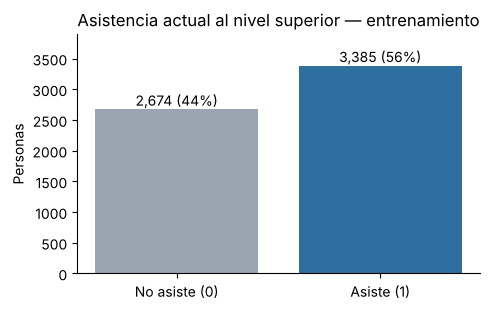

In [20]:
# Gráfico del balance de clases en el conjunto de entrenamiento
entrenamiento = dataset[dataset["particion"] == "entrenamiento"]
clases = entrenamiento["asiste_superior"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(["No asiste (0)", "Asiste (1)"], clases.values, color=["#9aa5b1", "#2f6f9f"])
for i, v in enumerate(clases.values):
    ax.text(i, v + 60, f"{v:,} ({v / clases.sum():.0%})", ha="center")
ax.set_ylabel("Personas")
ax.set_title("Asistencia actual al nivel superior — entrenamiento")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, clases.max() * 1.15)
plt.tight_layout()
plt.savefig("../reports/figures/balance_clases.png", dpi=120)

Las clases están **equilibradas** en entrenamiento (alrededor de 56 % asiste y 44 % no asiste) y la prueba tiene una proporción parecida.

In [21]:
# Guardado del dataset final (una fila por persona, con la partición)
dataset.to_csv("../data/processed/eph_jovenes_asistencia_superior.csv", index=False)
print("Dataset guardado en data/processed/eph_jovenes_asistencia_superior.csv")

Dataset guardado en data/processed/eph_jovenes_asistencia_superior.csv


## Resumen

| | |
|---|---|
| Fuente | EPH continua – INDEC (2T 2025 a 1T 2026), descargada el 22/10/2026 |
| Archivos originales | 8 (4 bases de personas + 4 de hogares), 178.474 personas en total |
| Población | Jóvenes de 18 a 24 años con secundario completo, sin estudio superior terminado, residentes en 31 aglomerados urbanos |
| Observaciones de la población | 13.883 (3 con respuesta desconocida, excluidas) |
| Instancias del dataset final | 9.663 personas (una fila por persona) |
| Partición | Entrenamiento 6.059 (2025) · Prueba 3.497 (1T 2026) · 107 excluidos por vivienda compartida |
| Columnas | 28 |
| Variable objetivo | `asiste_superior` (1 = asiste actualmente al nivel superior) |
| Tipo de problema | Clasificación binaria supervisada |

Siguiente paso: `2.0-lei-analisis-exploratorio.ipynb`.